# Chargement et Analyse Exploratoire des Données (EDA)

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [ ]:
df = pd.read_csv('../data/raw/student_mental_health.csv')

print("=== 1. DIMENSIONS ===")
print(f"Nombre de lignes   : {df.shape[0]}")
print(f"Nombre de colonnes : {df.shape[1]}")

print("\n=== 2. APERÇU DES 5 PREMIÈRES LIGNES ===")
print(df.head())

print("\n=== 3. INFORMATIONS SUR LES TYPES DE DONNÉES ET LA MÉMOIRE ===")
df.info()

=== 1. DIMENSIONS ===
Nombre de lignes   : 2000
Nombre de colonnes : 17

=== 2. APERÇU DES 5 PREMIÈRES LIGNES ===


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium



=== 3. INFORMATIONS SUR LES TYPES DE DONNÉES ET LA MÉMOIRE ===
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-n

In [18]:
num_duplicates = df.duplicated().sum()
print(f"Nombre de lignes en double : {num_duplicates}")

missing_summary = pd.DataFrame({
    'Valeurs Manquantes': df.isnull().sum(),
    'Pourcentage (%)': (df.isnull().sum() / len(df)) * 100
}).sort_values(by='Valeurs Manquantes', ascending=False)

print("\n=== VALEURS MANQUANTES PAR COLONNE ===")
print(missing_summary[missing_summary['Valeurs Manquantes'] > 0])

print("\n=== VÉRIFICATION DES MIN/MAX ET DES VALEURS ABERRANTES ===")
numeric_cols = df.select_dtypes(include=[np.number]).columns
print(df[numeric_cols].describe().T[['min', '25%', '50%', '75%', 'max']])

Nombre de lignes en double : 0

=== VALEURS MANQUANTES PAR COLONNE ===
                    Valeurs Manquantes  Pourcentage (%)
Financial_Stress                    91             4.55
Diet_Quality                        69             3.45
Sleep_Hours                         62             3.10
Social_Media_Hours                  58             2.90
Family_Support                      54             2.70
Attendance_Rate                     47             2.35
GPA                                 38             1.90

=== VÉRIFICATION DES MIN/MAX ET DES VALEURS ABERRANTES ===
                       min     25%    50%    75%     max
Age                   17.0  20.000  21.00  23.00   29.00
Year_of_Study          1.0   1.000   2.00   4.00    5.00
Sleep_Hours            3.3   6.000   6.70   7.60   10.00
Study_Hours_Per_Week   2.4  16.000  19.80  24.00   38.30
GPA                    1.5   2.320   2.56   2.79    3.66
Social_Media_Hours     2.1   5.225   6.00   6.70   10.00
Screen_Time_Hours     

In [13]:
print("=== STATISTIQUES DES VARIABLES NUMÉRIQUES ===")
print(df.describe().T)

print("\n=== STATISTIQUES DES VARIABLES CATÉGORIELLES ===")
print(df.describe(include=['object']).T)

=== STATISTIQUES DES VARIABLES NUMÉRIQUES ===
                       count       mean       std   min     25%    50%    75%  \
Age                   2000.0  21.131500  2.139275  17.0  20.000  21.00  23.00   
Year_of_Study         2000.0   2.630000  1.316802   1.0   1.000   2.00   4.00   
Sleep_Hours           1938.0   6.758875  1.127072   3.3   6.000   6.70   7.60   
Study_Hours_Per_Week  2000.0  19.997900  5.719274   2.4  16.000  19.80  24.00   
GPA                   1962.0   2.562503  0.343993   1.5   2.320   2.56   2.79   
Social_Media_Hours    1942.0   6.013955  1.153422   2.1   5.225   6.00   6.70   
Screen_Time_Hours     2000.0   8.548500  1.657571   3.3   7.400   8.50   9.70   
Financial_Stress      1909.0   5.956260  1.893941   1.4   4.500   6.10   7.40   
Family_Support        1946.0   6.518345  1.844639   1.7   5.100   6.70   8.00   
Attendance_Rate       1953.0  85.080236  7.224118  54.4  80.300  85.10  90.00   

                         max  
Age                    29.00  


C:\Users\achra\AppData\Local\Temp\ipykernel_48988\1172887235.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.describe(include=['object']).T)


=== DISTRIBUTION DE LA VARIABLE CIBLE ===
                    Effectif  Proportion (%)
Mental_Health_Risk                          
High                     680            34.0
Medium                   660            33.0
Low                      660            33.0


C:\Users\achra\AppData\Local\Temp\ipykernel_48988\2445883665.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Mental_Health_Risk', order=['Low', 'Medium', 'High'], palette='Set2', ax=ax[0])


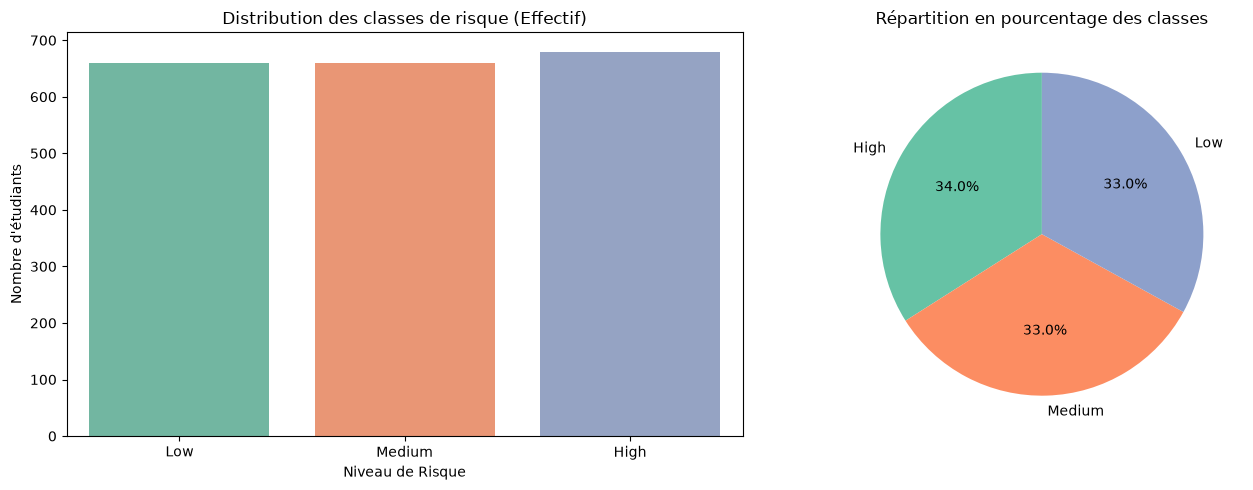

In [ ]:
target_counts = df['Mental_Health_Risk'].value_counts()
target_props = df['Mental_Health_Risk'].value_counts(normalize=True) * 100

target_df = pd.DataFrame({
    'Effectif': target_counts,
    'Proportion (%)': target_props
})

print("=== DISTRIBUTION DE LA VARIABLE CIBLE ===")
print(target_df)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x='Mental_Health_Risk', order=['Low', 'Medium', 'High'], palette='Set2', ax=ax[0])
ax[0].set_title("Distribution des classes de risque (Effectif)")
ax[0].set_xlabel("Niveau de Risque")
ax[0].set_ylabel("Nombre d'étudiants")

# Graphique camembert (Pie Chart)
ax[1].pie(target_props, labels=target_props.index, autopct='%1.1f%%', colors=sns.color_palette('Set2'), startangle=90)
ax[1].set_title("Répartition en pourcentage des classes")

plt.tight_layout()
plt.show()

C:\Users\achra\AppData\Local\Temp\ipykernel_48988\2340493084.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Mental_Health_Risk', y=col, order=['Low', 'Medium', 'High'], palette='Set2', ax=axes[i])
C:\Users\achra\AppData\Local\Temp\ipykernel_48988\2340493084.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Mental_Health_Risk', y=col, order=['Low', 'Medium', 'High'], palette='Set2', ax=axes[i])
C:\Users\achra\AppData\Local\Temp\ipykernel_48988\2340493084.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=d

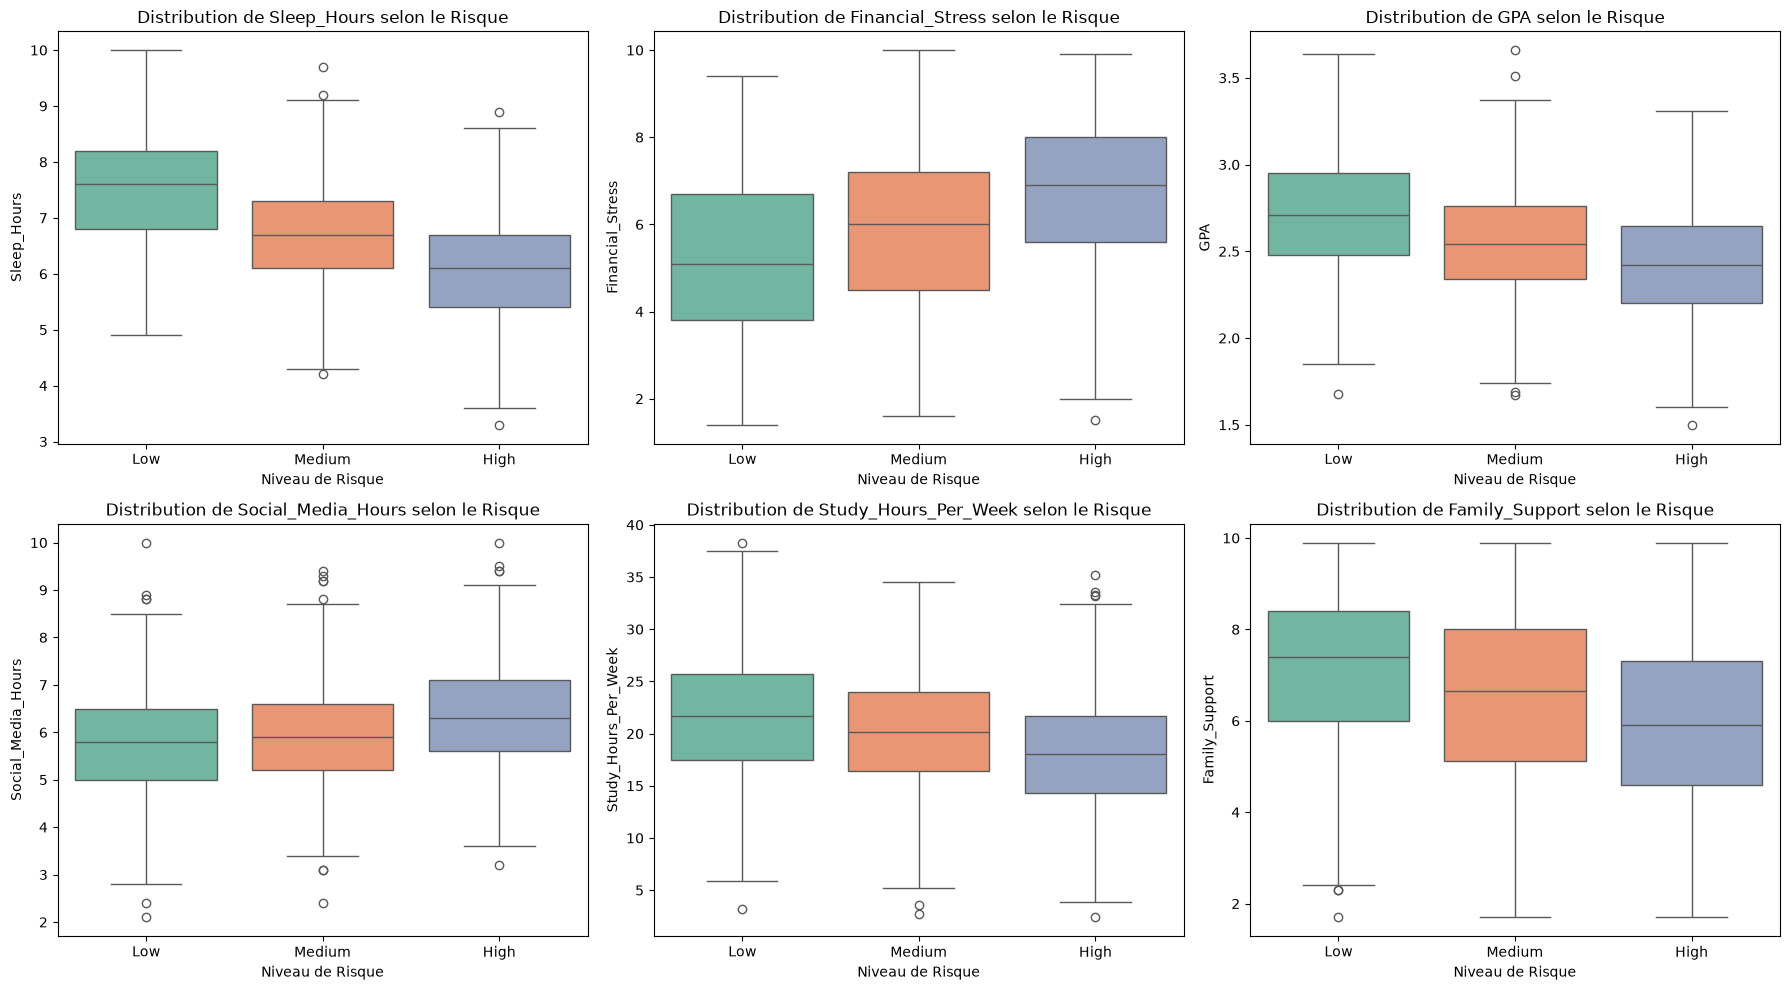

In [20]:

key_num_features = ['Sleep_Hours', 'Financial_Stress', 'GPA', 'Social_Media_Hours', 'Study_Hours_Per_Week', 'Family_Support']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(key_num_features):
    sns.boxplot(data=df, x='Mental_Health_Risk', y=col, order=['Low', 'Medium', 'High'], palette='Set2', ax=axes[i])
    axes[i].set_title(f"Distribution de {col} selon le Risque")
    axes[i].set_xlabel("Niveau de Risque")

plt.tight_layout()
plt.show()

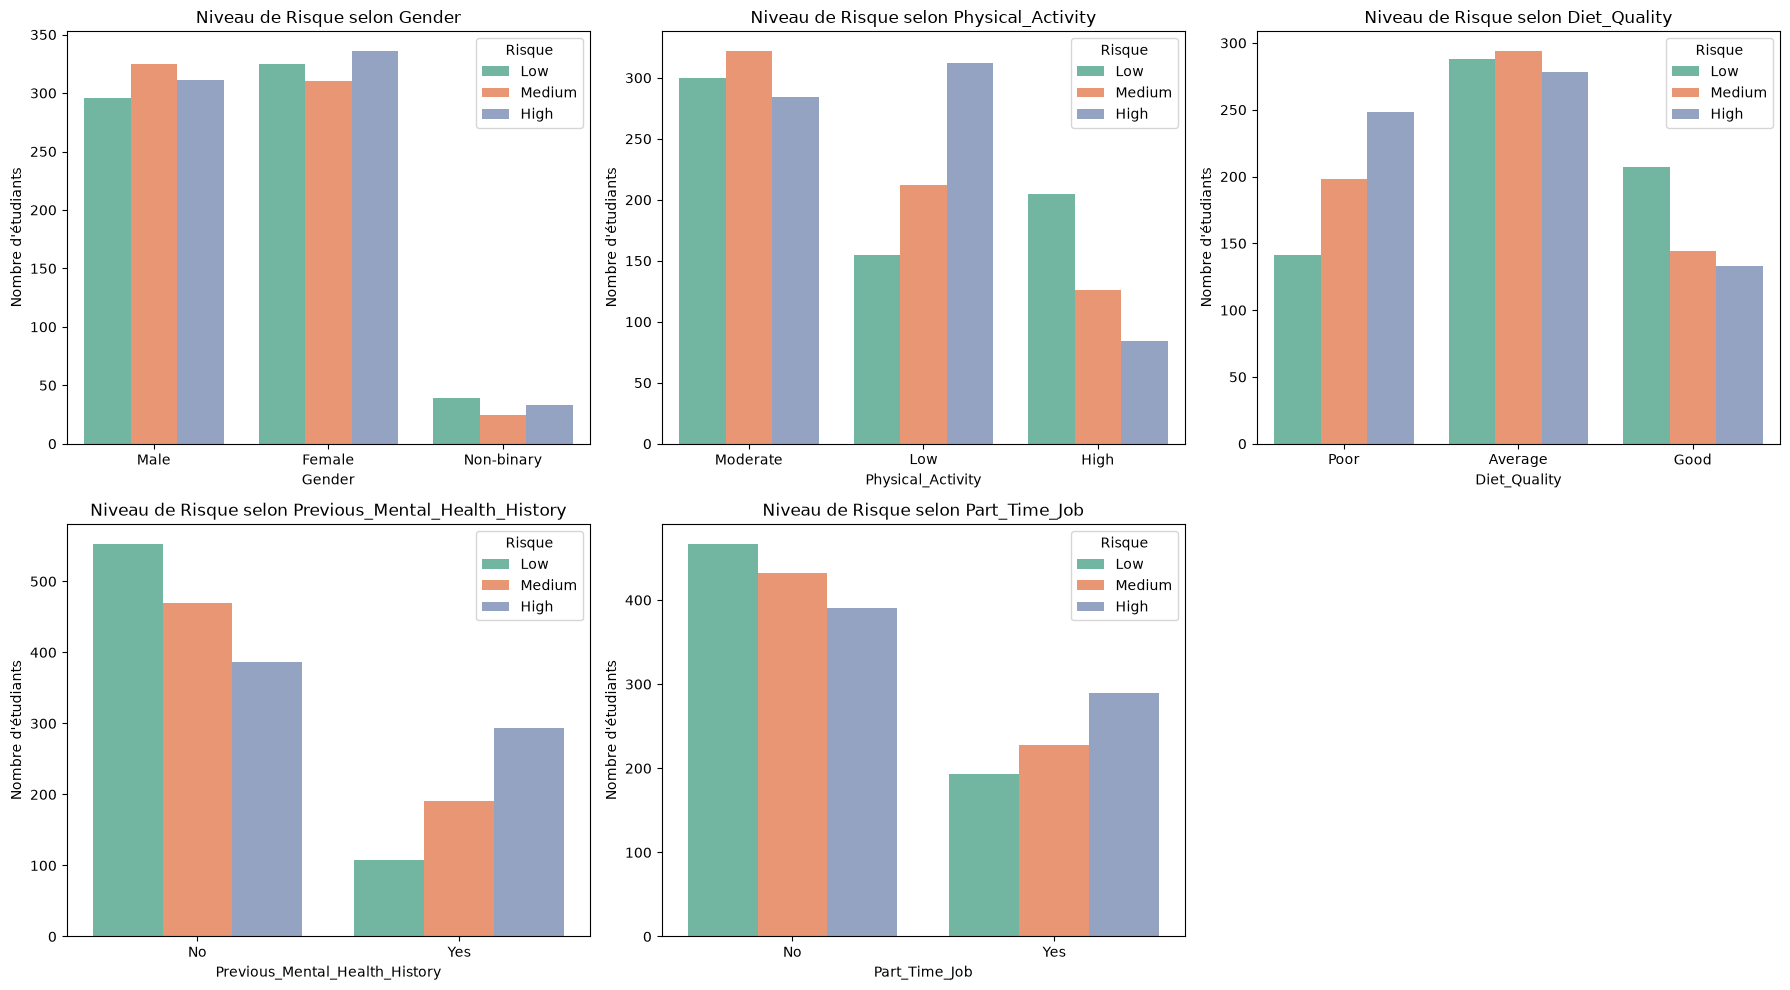

In [21]:
cat_cols = ['Gender', 'Physical_Activity', 'Diet_Quality', 'Previous_Mental_Health_History', 'Part_Time_Job']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, hue='Mental_Health_Risk', hue_order=['Low', 'Medium', 'High'], palette='Set2', ax=axes[i])
    axes[i].set_title(f"Niveau de Risque selon {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Nombre d'étudiants")
    axes[i].legend(title="Risque")

if len(cat_cols) < len(axes):
    fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

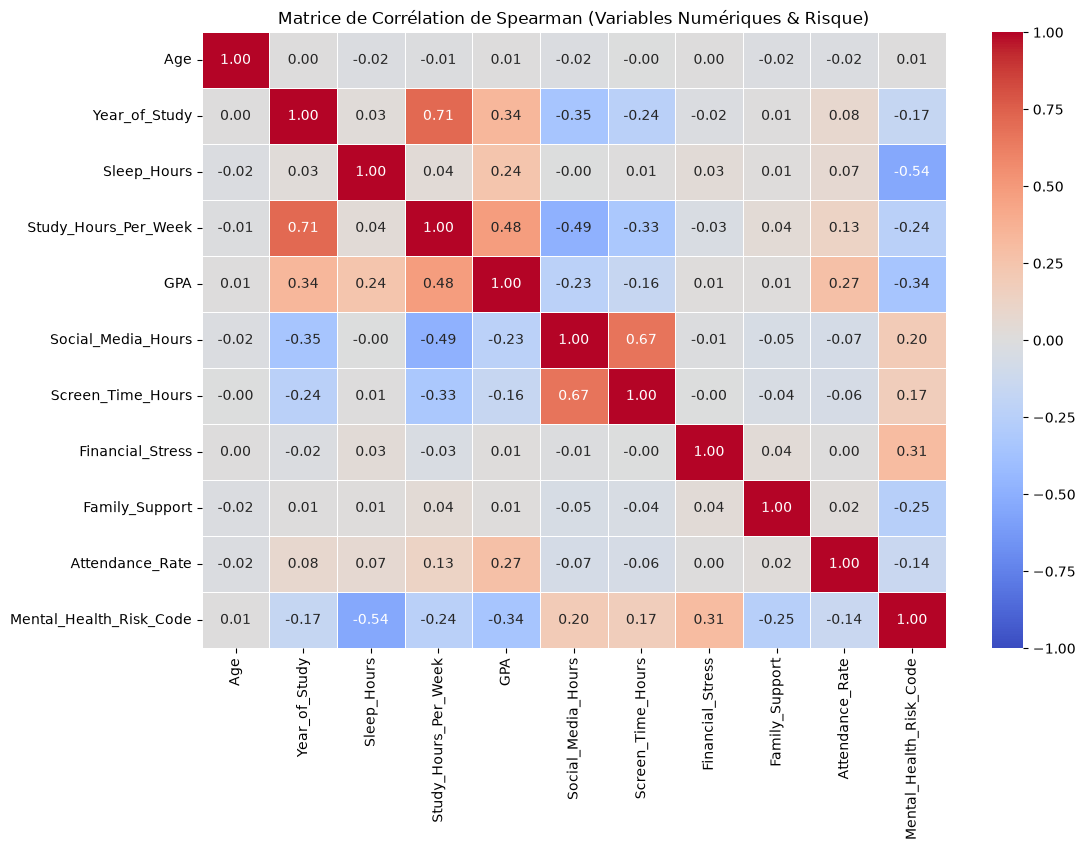

In [22]:
df_corr = df.copy()
df_corr['Mental_Health_Risk_Code'] = df_corr['Mental_Health_Risk'].map({'Low': 0, 'Medium': 1, 'High': 2})

# Sélection des colonnes numériques
num_df = df_corr.select_dtypes(include=[np.number])

# Calcul de la matrice de corrélation
corr_matrix = num_df.corr(method='spearman')

# Affichage de la carte thermique (Heatmap)
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matrice de Corrélation de Spearman (Variables Numériques & Risque)")
plt.show()

=== CORRÉLATION DES VARIABLES NUMÉRIQUES AVEC LE NIVEAU DE RISQUE ===
                      Corrélation (Spearman)
Sleep_Hours                        -0.541219
GPA                                -0.344298
Financial_Stress                    0.311370
Family_Support                     -0.250298
Study_Hours_Per_Week               -0.240049
Social_Media_Hours                  0.198289
Screen_Time_Hours                   0.173464
Year_of_Study                      -0.165839
Attendance_Rate                    -0.141808
Age                                 0.005131


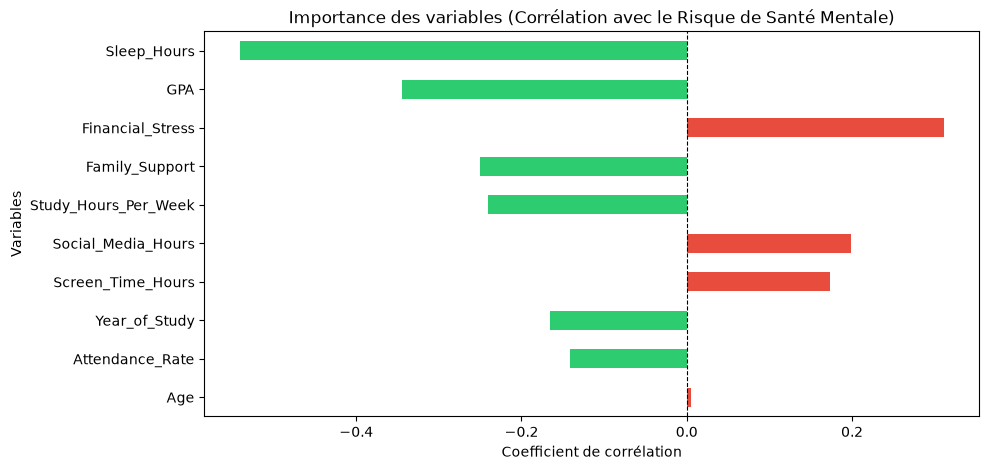

In [23]:
risk_correlations = corr_matrix['Mental_Health_Risk_Code'].drop('Mental_Health_Risk_Code').sort_values(key=abs, ascending=False)

print("=== CORRÉLATION DES VARIABLES NUMÉRIQUES AVEC LE NIVEAU DE RISQUE ===")
print(pd.DataFrame({'Corrélation (Spearman)': risk_correlations}))

# Visualisation des corrélations principales
plt.figure(figsize=(10, 5))
colors = ['#e74c3c' if val > 0 else '#2ecc71' for val in risk_correlations]
risk_correlations.plot(kind='barh', color=colors)
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.title("Importance des variables (Corrélation avec le Risque de Santé Mentale)")
plt.xlabel("Coefficient de corrélation")
plt.ylabel("Variables")
plt.gca().invert_yaxis()
plt.show()